# Practical 12 — Hierarchical (Agglomerative) Clustering

**Aim:** Build a hierarchy of clusters bottom-up, read a **dendrogram**, compare linkage methods and cut the tree into
flat clusters; evaluate the result.

**Dataset:** Iris (150 flowers, 4 measurements; UCI repository, bundled with scikit-learn). Species labels are **not**
used for clustering – only afterwards to judge the result.

**Idea – agglomerative algorithm:**
1. Start with every point as its own cluster (n clusters).
2. Compute the distances between all clusters.
3. **Merge the two closest clusters** and record the merge distance.
4. Repeat until a single cluster remains. The record of merges is the **dendrogram**; cutting it at a chosen height gives k clusters.

**Linkage** defines the distance between two *clusters*:
* `single` – closest pair of points (can chain clusters together) · `complete` – farthest pair (compact clusters)
* `average` – mean of all pairwise distances · `ward` – merge that increases the within-cluster variance the least.

As in Practical 11, the supervised train/test and k-fold protocol does not apply; we use internal and external clustering indices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)

## Step 1 — Load and scale the data

In [2]:
iris = load_iris(as_frame=True)
X_df = iris.data
y_true = iris.target.values
species = np.array(iris.target_names)
print("Shape:", X_df.shape, "| missing values:", int(X_df.isna().sum().sum()))
print("True species counts (not used for clustering):", np.bincount(y_true))
display(X_df.head())

X = StandardScaler().fit_transform(X_df)
print("\nScaled means ≈ 0:", X.mean(axis=0).round(3), "| stds = 1:", X.std(axis=0).round(3))

Shape: (150, 4) | missing values: 0
True species counts (not used for clustering): [50 50 50]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Scaled means ≈ 0: [-0. -0. -0. -0.] | stds = 1: [1. 1. 1. 1.]


## Step 2 — The first merges, step by step
1. `pdist` computes the distance between every pair of the 150 points (150·149/2 = 11 175 distances).
2. `linkage(..., method="ward")` repeatedly merges the closest pair of clusters and returns an (n−1)×4 matrix.
   Each row = **[cluster A, cluster B, merge distance, size of the new cluster]**. New clusters get ids 150, 151, 152, …
3. We check that the very first merge really joins the two closest points.

In [3]:
D = pdist(X, metric="euclidean")
print("Step 2.1  number of pairwise distances:", len(D))

Z = linkage(X, method="ward")
print("Step 2.2  linkage matrix shape:", Z.shape, "(n-1 merges × 4 columns)")
print("First 8 merges:")
display(pd.DataFrame(Z[:8], columns=["cluster A", "cluster B", "distance", "new size"]).astype({"cluster A": int, "cluster B": int, "new size": int}))

dist_matrix = squareform(D); np.fill_diagonal(dist_matrix, np.inf)
i, j = np.unravel_index(np.argmin(dist_matrix), dist_matrix.shape)
print(f"\nStep 2.3  closest pair of points = ({min(i, j)}, {max(i, j)}) at distance {dist_matrix[i, j]:.4f}")
print(f"          first merge in Z          = ({int(Z[0, 0])}, {int(Z[0, 1])}) at distance {Z[0, 2]:.4f}")
print("          (Distance 0: Iris contains duplicate rows. For singleton clusters Ward's merge distance equals the point distance; later merge heights grow.)")

print("\nLast 3 merges (the big groups joining):")
display(pd.DataFrame(Z[-3:], columns=["cluster A", "cluster B", "distance", "new size"]).astype({"cluster A": int, "cluster B": int, "new size": int}))

Step 2.1  number of pairwise distances: 11175
Step 2.2  linkage matrix shape: (149, 4) (n-1 merges × 4 columns)
First 8 merges:


,cluster A,cluster B,distance,new size
0,101,142,0.0000,2
1,7,39,0.1212,2
2,10,48,0.1212,2
3,0,17,0.1316,2
4,9,34,0.1316,2
5,128,132,0.1316,2
6,127,138,0.1338,2
7,2,47,0.1338,2



Step 2.3  closest pair of points = (101, 142) at distance 0.0000
          first merge in Z          = (101, 142) at distance 0.0000
          (Distance 0: Iris contains duplicate rows. For singleton clusters Ward's merge distance equals the point distance; later merge heights grow.)

Last 3 merges (the big groups joining):


,cluster A,cluster B,distance,new size
0,290,293,8.0047,71
1,294,296,12.6368,101
2,295,297,27.2499,150


## Step 3 — Manual single-linkage on 6 points (tiny worked example)
Shows the loop explicitly: find the closest two clusters, merge, update distances (single linkage = minimum).

In [4]:
pts = X[[0, 1, 2, 50, 51, 100]]
labels_small = ["p0", "p1", "p2", "p50", "p51", "p100"]
clusters = {n: [n] for n in labels_small}
d = squareform(pdist(pts)); names = list(labels_small)
step = 1
while len(clusters) > 1:
    keys = list(clusters)
    best = (np.inf, None, None)
    for a in range(len(keys)):
        for b in range(a + 1, len(keys)):
            dd = min(d[labels_small.index(p), labels_small.index(q)] for p in clusters[keys[a]] for q in clusters[keys[b]])   # single linkage
            if dd < best[0]: best = (dd, keys[a], keys[b])
    dd, a, b = best
    print(f"Step {step}: merge {clusters[a]} + {clusters[b]} at distance {dd:.3f}")
    clusters[a + "+" + b] = clusters.pop(a) + clusters.pop(b)
    step += 1

Step 1: merge ['p1'] + ['p2'] at distance 0.523
Step 2: merge ['p50'] + ['p51'] at distance 0.748
Step 3: merge ['p0'] + ['p1', 'p2'] at distance 0.846
Step 4: merge ['p100'] + ['p50', 'p51'] at distance 1.590
Step 5: merge ['p0', 'p1', 'p2'] + ['p100', 'p50', 'p51'] at distance 2.998


## Step 4 — Dendrogram
* Leaves = samples, vertical axis = distance at which clusters merge.
* A **long vertical gap** before the next merge means the clusters being joined are far apart → cut there.
* A horizontal cut line crossing *k* vertical lines gives *k* clusters.

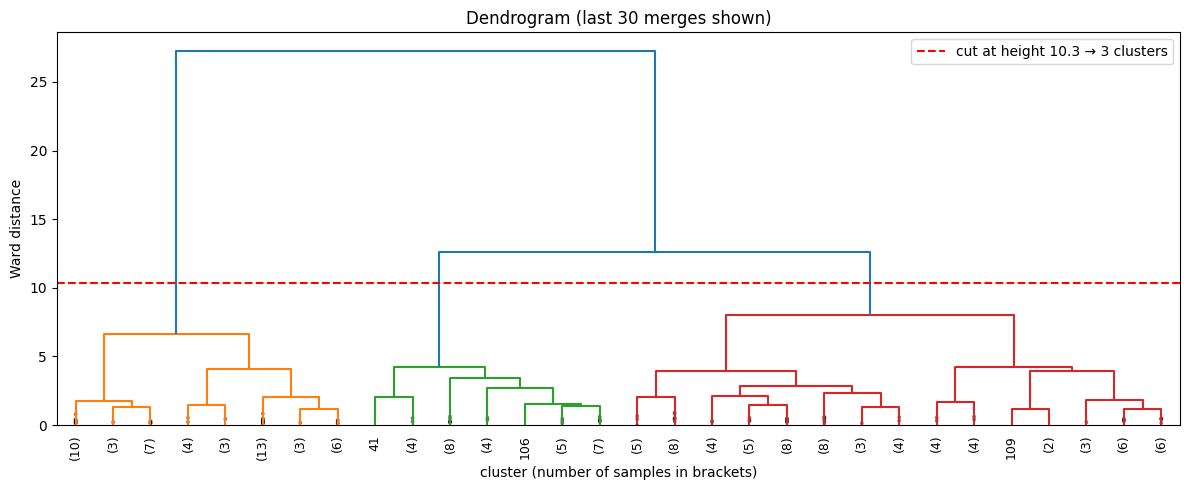

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
cut_height = 0.5 * (Z[-3, 2] + Z[-2, 2])                      # between the 3-cluster and the 2-cluster merge levels
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True, ax=ax,
           color_threshold=cut_height)
ax.axhline(cut_height, color="red", ls="--", label=f"cut at height {cut_height:.1f} → 3 clusters")
ax.set(xlabel="cluster (number of samples in brackets)", ylabel="Ward distance", title="Dendrogram (last 30 merges shown)"); ax.legend()
plt.tight_layout(); plt.show()

## Step 5 — Compare linkage methods
**Cophenetic correlation** measures how faithfully the dendrogram preserves the original pairwise distances
(closer to 1 = better). We also cut every tree into 3 clusters and compare with the real species.

,cophenetic_corr,cluster_sizes,silhouette,davies_bouldin,ARI_vs_species,NMI_vs_species
single,0.83,"[100, 49, 1]",0.5046,0.4929,0.5584,0.7201
complete,0.7515,"[77, 24, 49]",0.4496,0.7584,0.5726,0.653
average,0.8544,"[50, 3, 97]",0.4803,0.5753,0.5621,0.7131
ward,0.8226,"[49, 30, 71]",0.4467,0.8035,0.6153,0.6755


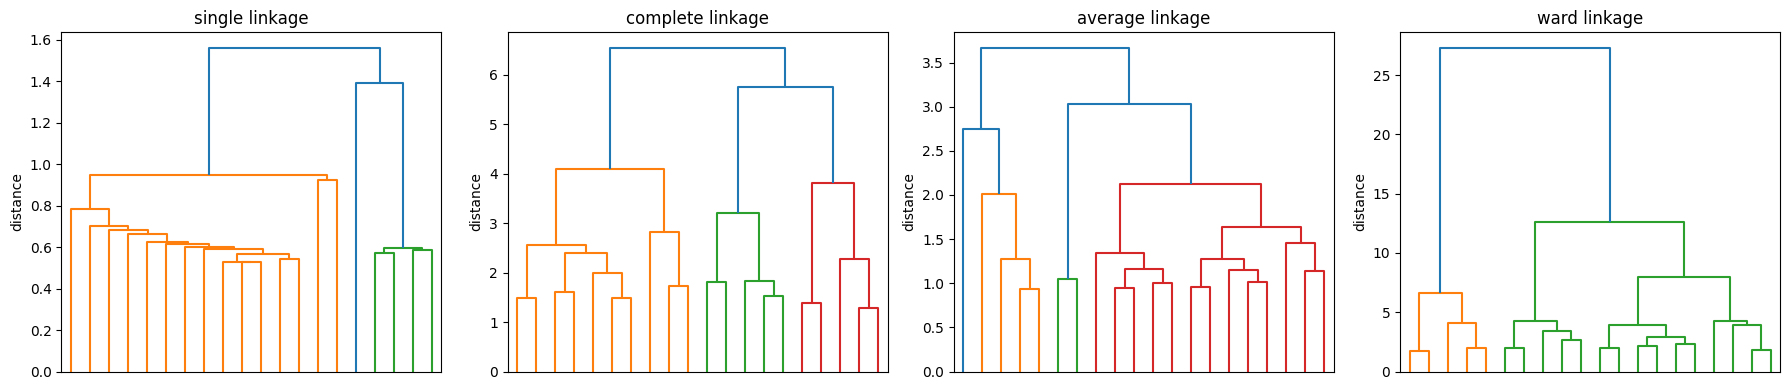

In [6]:
rows = {}
trees = {}
for method in ["single", "complete", "average", "ward"]:
    Zm = linkage(X, method=method)
    trees[method] = Zm
    lab = fcluster(Zm, t=3, criterion="maxclust") - 1              # fcluster labels start at 1
    c, _ = cophenet(Zm, D)
    rows[method] = {"cophenetic_corr": c, "cluster_sizes": str(np.bincount(lab).tolist()),
                    "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab),
                    "ARI_vs_species": adjusted_rand_score(y_true, lab), "NMI_vs_species": normalized_mutual_info_score(y_true, lab)}
comparison = pd.DataFrame(rows).T
display(comparison)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (m, Zm) in zip(axes, trees.items()):
    dendrogram(Zm, truncate_mode="lastp", p=20, no_labels=True, ax=ax)
    ax.set_title(f"{m} linkage"); ax.set_ylabel("distance")
plt.tight_layout(); plt.show()

## Step 6 — Final model with scikit-learn's `AgglomerativeClustering` (Ward, 3 clusters)
It performs the same merging procedure and stops when 3 clusters are left.

In [7]:
agg = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X)
labels = agg.labels_
labels_scipy = fcluster(trees["ward"], t=3, criterion="maxclust") - 1
print("Cluster sizes:", np.bincount(labels))
print("Number of merges performed:", len(agg.children_), "(= n_samples − 1)")
print("Same partition as SciPy's Ward cut (ARI = 1 means identical):", adjusted_rand_score(labels, labels_scipy))

print("\nInternal indices   : silhouette = %.4f | Davies–Bouldin = %.4f (lower is better)"
      % (silhouette_score(X, labels), davies_bouldin_score(X, labels)))
print("External indices   : ARI = %.4f | NMI = %.4f" % (adjusted_rand_score(y_true, labels), normalized_mutual_info_score(y_true, labels)))
display(pd.crosstab(pd.Series(species[y_true], name="true species"), pd.Series(labels, name="cluster")))

Cluster sizes: [71 49 30]
Number of merges performed: 149 (= n_samples − 1)
Same partition as SciPy's Ward cut (ARI = 1 means identical): 1.0

Internal indices   : silhouette = 0.4467 | Davies–Bouldin = 0.8035 (lower is better)
External indices   : ARI = 0.6153 | NMI = 0.6755


cluster,0,1,2
true species,,,
setosa,0,49,1
versicolor,23,0,27
virginica,48,0,2


## Step 7 — Visualise the clusters (PCA to 2-D)

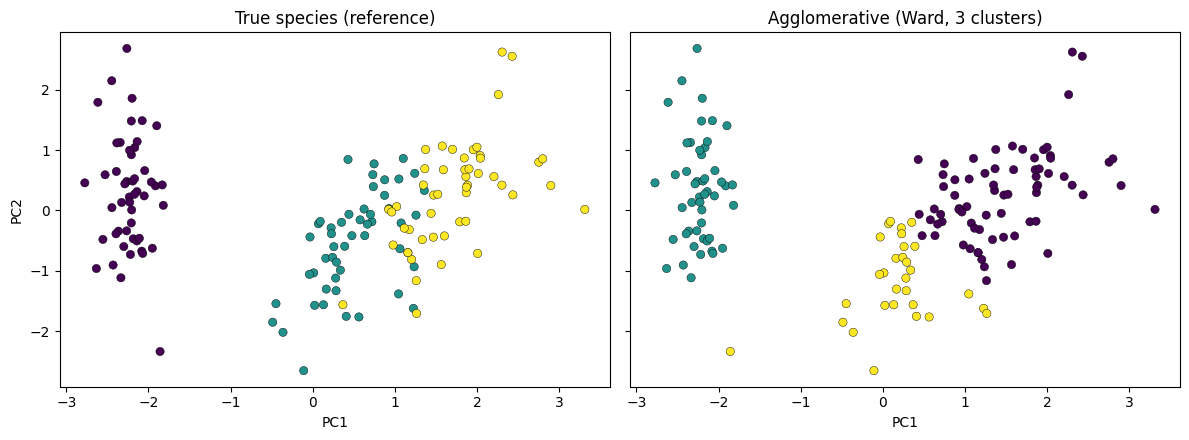

In [8]:
P = PCA(n_components=2).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
ax[0].scatter(P[:, 0], P[:, 1], c=y_true, cmap="viridis", edgecolor="k", linewidth=0.3); ax[0].set_title("True species (reference)")
ax[1].scatter(P[:, 0], P[:, 1], c=labels, cmap="viridis", edgecolor="k", linewidth=0.3); ax[1].set_title("Agglomerative (Ward, 3 clusters)")
for a in ax: a.set_xlabel("PC1")
ax[0].set_ylabel("PC2"); plt.tight_layout(); plt.show()

## Step 8 — How many clusters? Silhouette for different cuts of the same tree

In [9]:
rows = []
for k in range(2, 9):
    lab = fcluster(trees["ward"], t=k, criterion="maxclust")
    rows.append({"k": k, "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab)})
ks = pd.DataFrame(rows).set_index("k")
display(ks.round(4))
print("Largest gaps between consecutive merge heights (big gap ⇒ natural cut):")
heights = Z[:, 2]
gaps = pd.DataFrame({"clusters_before_merge": range(len(heights) + 1, 1, -1), "height": heights, "gap_to_next": np.r_[np.diff(heights), np.nan]}).tail(6)
display(gaps.round(3))

,silhouette,davies_bouldin
k,,
2,0.5770,0.5917
3,0.4467,0.8035
4,0.4006,0.9788
5,0.3306,0.9742
6,0.3149,0.9895
7,0.3170,0.9706
8,0.3109,0.9467


Largest gaps between consecutive merge heights (big gap ⇒ natural cut):


,clusters_before_merge,height,gap_to_next
143,7,4.227,0.016
144,6,4.243,2.364
145,5,6.608,1.397
146,4,8.005,4.632
147,3,12.637,14.613
148,2,27.250,NaN


### Conclusion
* The dendrogram is the complete history of merges: each row of the linkage matrix records which two clusters merged, at what distance, and the size of the new cluster; the first merge joins the two closest points.
* The linkage choice matters. **Single** linkage "chains" points together (one giant cluster of ~100 plus a single outlier); **average** linkage also isolates a tiny cluster; **Ward** and **complete** give more balanced clusters, and Ward has the best agreement with the true species (highest ARI of the four).
* The agreement is only moderate (ARI ≈ 0.6) because *versicolor* and *virginica* overlap; *setosa* is cleanly separated. The merge-height gaps reflect this: the biggest gap is before the final merge (2 natural groups = setosa vs the rest), the next biggest suggests 3.
* Unlike K-means, no k has to be chosen before running and the result is deterministic, but the O(n²) memory/time cost makes it unsuitable for very large datasets.